In [1]:
from pathlib import Path
import os 

import pandas as pd
import numpy as np
import scanpy as sc 
import matplotlib.pyplot as plt 
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
from matplotlib.patches import Patch
from matplotlib.font_manager import FontProperties

from dotenv import dotenv_values

In [ ]:
# Setting up filepaths from config
CONFIG = dotenv_values("config.env") 
DATADIR = Path(CONFIG['DATADIR'])

OUTDIR = DATADIR / "publication" / "Fig_03"
os.makedirs(OUTDIR, exist_ok=True)

OBJECTS_DIR = DATADIR / "9_objects"
SC_ADATA_FP = OBJECTS_DIR / "singlecell" / "hypomap3d_singlecell_control.h5ad" 

OVERVIEW_FP = OUTDIR / "dmh_cluster_overview.tsv"

In [3]:
adata_sc = sc.read_h5ad(SC_ADATA_FP, backed="r")

In [4]:
dmh_cluster_overview = pd.read_csv(OVERVIEW_FP, delimiter="\t")

# manually overwriting some of the colors
color_mapping_L2 = {
 'Gl2-26': '#F781BF',
 'Gl2-25': '#B05B3A' ,
 'Gl2-11': '#E8D430',
 'Gl2-36': '#58386e',
 'Gb2-64': '#CB6651',
 'Gb2-57': '#FFAF13',
 'Gb2-54': "#47A265",
 'Gb2-49': '#4C71A4',
 'Gb2-43': "#E41A1C"
 }

dmh_cluster_overview["L2_ID"] = dmh_cluster_overview.L2_descr.apply(lambda x: x.split(" ")[0])
dmh_cluster_overview.color_L2 = dmh_cluster_overview.L2_ID.map(color_mapping_L2)

color_mapping_L2 = dmh_cluster_overview.loc[:, ["L2_descr", "color_L2"]].drop_duplicates().set_index("L2_descr").to_dict()["color_L2"]

dmh_cluster_overview.head(3)

,L3_ID,L3_descr,L2_descr,region_rank,relative_mass,cum_mass,flag,color_L3,color_L2,L2_ID
0,Gl3-84,Gl3-84 DMH Nr2f1,Gl2-26 DMH Nkx2-4,1,0.256136,0.000000,NaN,#518C55,#F781BF,Gl2-26
1,Gl3-83,Gl3-83 DMH Pdyn,Gl2-26 DMH Nkx2-4,1,0.287700,0.000000,NaN,#8AA716,#F781BF,Gl2-26
2,Gl3-82,Gl3-82 VMH Npy2r,Gl2-25 DMH Hmx2,3,0.149167,0.385678,NaN,#8A823C,#B05B3A,Gl2-25


## Plotting L2 of clusters assigned to DMH

In [5]:
dmh_clusters_l3 = dmh_cluster_overview.L3_descr.unique()

In [6]:
adata_sc.obs["DMH_colors"] = "lightgrey" 
valid_l2_mask = adata_sc.obs.L2_descr.isin(list(color_mapping_L2.keys())) 
adata_sc.obs.loc[valid_l2_mask, "DMH_colors"] = adata_sc.obs.loc[valid_l2_mask, "L2_descr"].map(color_mapping_L2)
invalid_l3_mask = ~adata_sc.obs.L3_descr.isin(dmh_clusters_l3)
valid_l2_invalid_l3_mask = valid_l2_mask & invalid_l3_mask 
adata_sc.obs.loc[valid_l2_invalid_l3_mask, "DMH_colors"] = "dimgray"

In [7]:
L3_color_map = adata_sc.obs.loc[:, ["L3_descr", "DMH_colors"]].drop_duplicates().set_index("L3_descr").to_dict()["DMH_colors"]

In [8]:
scattersize = 0.075

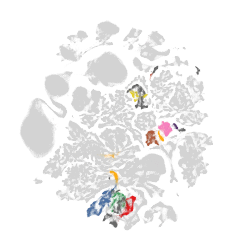

In [9]:

fig, ax = plt.subplots(figsize=(3, 3), ) 
sc.pl.umap(adata_sc, color="L3_descr", ax=ax, s=scattersize, show=False, 
    palette=L3_color_map, legend_loc=None )

# Rasterize only the scatter points (not text)
for coll in ax.collections:
    coll.set_rasterized(True)

# Customize: remove title, borders, ticks, labels
ax.set_title("")
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_aspect('equal')

fig.canvas.draw()

plt.savefig(OUTDIR / "DMH_colors_C_UMAP.pdf", format="pdf", dpi=300, bbox_inches="tight") 
plt.show()

### L4 DMH Glp1r

In [10]:
l4 = adata_sc[adata_sc.obs.L3_ID == "Gb3-146",:].to_memory()

In [11]:
sc.pp.neighbors(l4, n_neighbors=15, use_rep="X_embed")
sc.tl.umap(l4, )

In [12]:
gsx1_L4_cmap = {
    'Gb4-388 DMH Glp1r.Slc26a7': "#d8b585", 
    'Gb4-389 DMH Glp1r.Erg': "#8c4205", 
    'Gb4-390 DMH Glp1r.Ghrh': "#3e566f", 
    'Gb4-391 DMH Glp1r.Tbx19': "#7e791e", 
    'Gb4-392 DMH Glp1r.Nfix': "#5b1e34"
}

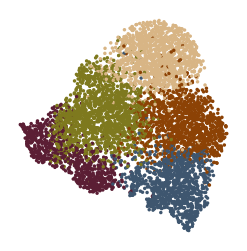

In [14]:

fig, ax = plt.subplots(figsize=(3,3), ) 
sc.pl.umap(l4, color="L4_descr", ax=ax, s=25, 
    show=False, palette=gsx1_L4_cmap, legend_loc=None 
    )

# Rasterize only the scatter points (not text)
for coll in ax.collections:
    coll.set_rasterized(True)

# Customize: remove title, borders, ticks, labels
ax.set_title("")
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_aspect('equal')

fig.canvas.draw()

plt.savefig(OUTDIR / "DMH_colors_L4_UMAP.pdf", format="pdf", dpi=300, bbox_inches="tight") 
plt.show()